# OLCFourStages - Test on Different Topologies

`olc_four_stages` with B = 3 buses on the line, cycle, star and wheel graph with 5 nodes each.

In [1]:
%config InlineBackend.figure_format = "retina"

import importlib.util
import sys, os

sys.path.insert(0, os.path.abspath(".."))

missing = [name for name in ("networkx", "matplotlib", "gurobipy")
           if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError(f"missing packages: {', '.join(missing)}. See the README of the repository.")
if importlib.util.find_spec("LineCover") is None:
    raise ImportError("LineCover not found. Run this notebook from the notebooks folder of the repository.")

import gurobipy as gp
from LineCover import *
from LineCover.SystemKit.network import Network
from LineCover.Metaheuristics import olc_four_stages, STAGES

print("Gurobi", gp.gurobi.version())

Gurobi (13, 0, 1)


In [2]:
SEED = 0
B = 3
N_NODES = 5

S = 20
LS_L_MAX = 5
PERT_L_MAX = 5
MAX_EVALUATIONS = 100_000
PH_RESTARTS = 250
PH_MAX_HOPS = 10**6

# The figures are written into this folder, overwriting files of the same name.
FIGURE_DIR = "OLCFourStages_Test_Topologies/figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

GRAPHS = {
    "line": get_line_graph_data,
    "cycle": get_cycle_graph_data,
    "star": get_star_graph_data,
    "wheel": get_wheel_graph_data,
}

Set parameter Username
Set parameter LicenseID to value 2771095
Academic license - for non-commercial use only - expires 2027-01-28
--- line ---
initial_solution         EA = 4.0000
phase_harmonisation_1    EA = 3.3333
route_ils                EA = 3.3333
phase_harmonisation_2    EA = 3.3333
b_1: P_b = 8, t_b = 1.0000


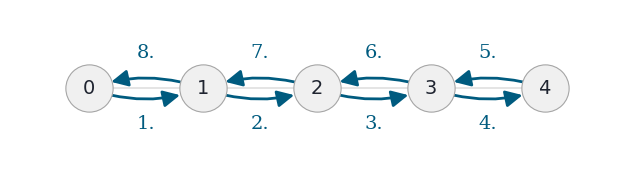

b_2: P_b = 8, t_b = 0.6667


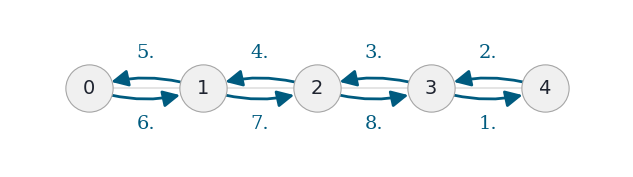

b_3: P_b = 8, t_b = 0.3333


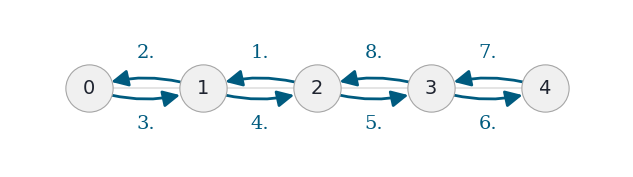

--- cycle ---
initial_solution         EA = 3.9167
phase_harmonisation_1    EA = 3.9000
route_ils                EA = 3.1800
phase_harmonisation_2    EA = 3.1308
b_1: P_b = 5, t_b = 0.2488


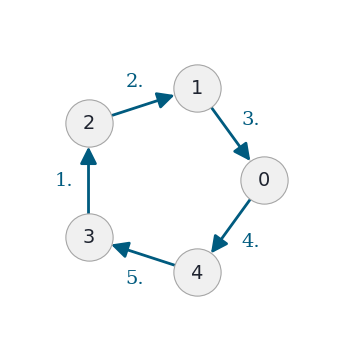

b_2: P_b = 5, t_b = 0.5565


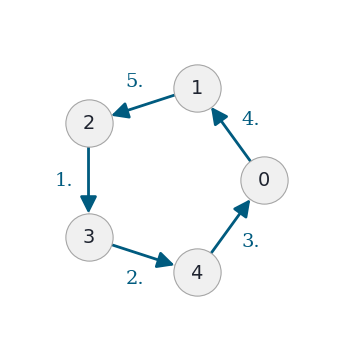

b_3: P_b = 5, t_b = 0.9411


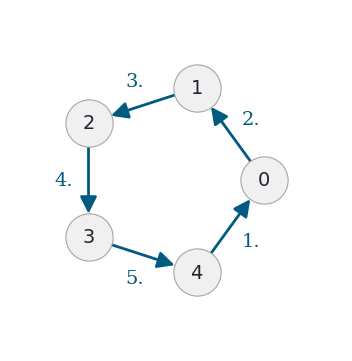

--- star ---
initial_solution         EA = 5.3500
phase_harmonisation_1    EA = 5.1652
route_ils                EA = 4.0214
phase_harmonisation_2    EA = 4.0000
b_1: P_b = 8, t_b = 0.5362


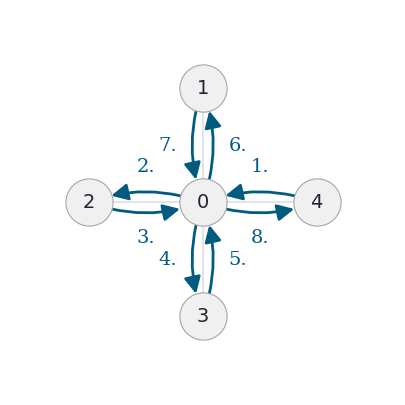

b_2: P_b = 8, t_b = 0.5362


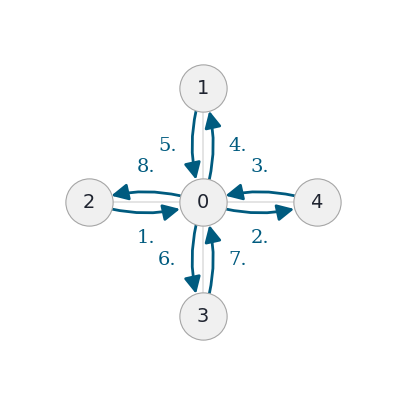

b_3: P_b = 8, t_b = 0.5362


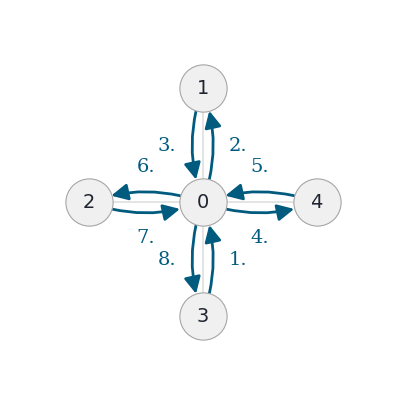

--- wheel ---
initial_solution         EA = 4.5875
phase_harmonisation_1    EA = 4.5786
route_ils                EA = 3.1300
phase_harmonisation_2    EA = 3.1195
b_1: P_b = 5, t_b = 0.9147


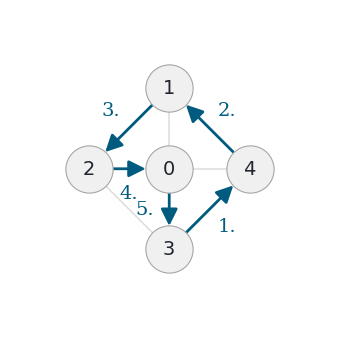

b_2: P_b = 5, t_b = 0.5142


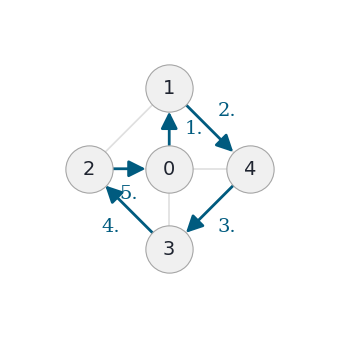

b_3: P_b = 5, t_b = 0.2262


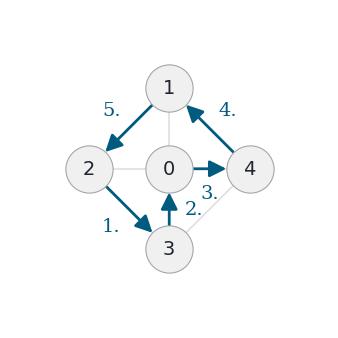

In [3]:
for name, graph_data in GRAPHS.items():
    edge_list, pos = graph_data(N_NODES)
    network = Network(edge_list, pos=pos, seed=SEED)

    result = olc_four_stages(
        network.graph, B,
        max_evaluations=MAX_EVALUATIONS, s=S,
        ph_restarts=PH_RESTARTS, ph_max_hops=PH_MAX_HOPS,
        ls_L_max=LS_L_MAX, pert_L_max=PERT_L_MAX,
        seed=SEED,
    )

    print(f"--- {name} ---")
    for stage in STAGES:
        print(f"{stage:<24} EA = {result.values[stage]:.4f}")

    for bid, bus in sorted(result.system.buses.items()):
        print(f"b_{bid}: P_b = {bus.P_b}, t_b = {bus.t_b:.4f}")
        network.visualize_bus(
            bus,
            filename=os.path.join(FIGURE_DIR, f"{name}_bus{bid}.pdf"),
            caption="",
        )